# British Airways: Customer Booking Prediction

Forage British Airways Data Science Job Simulation, Task 2.

**Question:** Can we predict whether a customer will complete a flight booking (`booking_complete` = 1) from booking, trip and customer-preference data?

**Dataset:** 50,000 customer bookings, 14 columns, provided by Forage.

**Steps:** EDA with simple hypotheses, feature engineering, Random Forest in a preprocessing pipeline, evaluation, feature importance, cross-validation, conclusions.

In [1]:
import pandas as pd

## 1. Load the data

#### Loading the dataset

In [2]:
df = pd.read_csv('../data/customer_booking.csv', encoding="ISO-8859-1")

## 2. Basic checks

#### Basic EDA process 

In [3]:
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [4]:
df.shape

(50000, 14)

In [5]:
df.columns

Index(['num_passengers', 'sales_channel', 'trip_type', 'purchase_lead',
       'length_of_stay', 'flight_hour', 'flight_day', 'route',
       'booking_origin', 'wants_extra_baggage', 'wants_preferred_seat',
       'wants_in_flight_meals', 'flight_duration', 'booking_complete'],
      dtype='object')

In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

In [7]:
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,1.000000,1.000000,1.000000,9.500000,1.000000


In [8]:
df.isnull().sum()

num_passengers           0
sales_channel            0
trip_type                0
purchase_lead            0
length_of_stay           0
flight_hour              0
flight_day               0
route                    0
booking_origin           0
wants_extra_baggage      0
wants_preferred_seat     0
wants_in_flight_meals    0
flight_duration          0
booking_complete         0
dtype: int64

No missing values in any column.

In [9]:
df["booking_complete"].value_counts()

booking_complete
0    42522
1     7478
Name: count, dtype: int64

## 3. Exploratory analysis: what is linked to booking completion?

### Hypothesis 1 — Purchase lead

In [10]:
df["booking_complete"].value_counts(normalize=True) * 100

booking_complete
0    85.044
1    14.956
Name: proportion, dtype: float64

In [11]:
df.groupby("booking_complete")["purchase_lead"].agg(["mean", "median", "min", "max"])

,mean,median,min,max
booking_complete,,,,
0,85.779926,52.0,0,704
1,80.167157,46.0,0,867


### Hypothesis 2 — Sales channel

In [12]:
pd.crosstab(
    df["sales_channel"],
    df["booking_complete"],
    normalize="index"
) * 100

booking_complete,0,1
sales_channel,,
Internet,84.523005,15.476995
Mobile,89.159843,10.840157


In [13]:
df.groupby("booking_complete")["purchase_lead"].describe()

,count,mean,std,min,25%,50%,75%,max
booking_complete,,,,,,,,
0,42522.0,85.779926,90.534130,0.0,22.0,52.0,117.0,704.0
1,7478.0,80.167157,89.836401,0.0,18.0,46.0,106.0,867.0


### Hypothesis 3 — Extra baggage

In [14]:
pd.crosstab(
    df["wants_extra_baggage"],
    df["booking_complete"],
    normalize="index"
) * 100

booking_complete,0,1
wants_extra_baggage,,
0,88.497071,11.502929
1,83.333832,16.666168


### Hypothesis 4 — Preferred seat

In [15]:
pd.crosstab(
    df["wants_preferred_seat"],
    df["booking_complete"],
    normalize="index"
) * 100

booking_complete,0,1
wants_preferred_seat,,
0,86.205621,13.794379
1,82.293912,17.706088


### Hypothesis 5 — In-flight meals

In [16]:
pd.crosstab(
    df["wants_in_flight_meals"],
    df["booking_complete"],
    normalize="index"
) * 100

booking_complete,0,1
wants_in_flight_meals,,
0,85.860420,14.139580
1,83.949057,16.050943


Sales channel and additional service preferences appear to have some relationship with booking completion. Internet users, customers requesting extra baggage, and customers requesting preferred seats all show higher completion rates. Purchase lead shows only a relatively small difference between completed and non-completed bookings, while in-flight meal preference shows a smaller difference. These are initial associations and will need to be tested using the machine learning model

### length_of_stay

In [17]:
df["length_of_stay"].describe()

count    50000.00000
mean        23.04456
std         33.88767
min          0.00000
25%          5.00000
50%         17.00000
75%         28.00000
max        778.00000
Name: length_of_stay, dtype: float64

In [18]:
df["stay_group"] = pd.cut(
    df["length_of_stay"],
    bins=[-1, 3, 7, 14, 30, 999],
    labels=["1-3 days", "4-7 days", "8-14 days", "15-30 days", "31+ days"]
)

In [19]:
pd.crosstab(
    df["stay_group"],
    df["booking_complete"],
    normalize="index"
) * 100

booking_complete,0,1
stay_group,,
1-3 days,82.163522,17.836478
4-7 days,80.568171,19.431829
15-30 days,89.904235,10.095765
31+ days,88.094104,11.905896


 ### flight_hour

In [20]:
df["flight_hour"].value_counts().sort_index()

flight_hour
0     1539
1     2089
2     2642
3     2655
4     2843
5     2851
6     3050
7     3126
8     3165
9     3132
10    3085
11    3110
12    3163
13    3101
14    2833
15    2234
16    1557
17     861
18     439
19     295
20     276
21     389
22     579
23     986
Name: count, dtype: int64

In [21]:
pd.crosstab(
    df["flight_hour"],
    df["booking_complete"],
    normalize="index"
) * 100

booking_complete,0,1
flight_hour,,
0,88.174139,11.825861
1,86.357109,13.642891
2,85.276306,14.723694
3,85.197740,14.802260
4,84.875132,15.124868
5,84.882497,15.117503
6,84.000000,16.000000
7,86.468330,13.531670
8,84.707741,15.292259


### booking_origin

In [22]:
df["booking_origin"].nunique()

104

In [23]:
df["booking_origin"].value_counts().head(15)

booking_origin
Australia        17872
Malaysia          7174
South Korea       4559
Japan             3885
China             3387
Indonesia         2369
Taiwan            2077
Thailand          2030
India             1270
New Zealand       1074
Singapore         1044
United States      456
Vietnam            388
Macau              304
Hong Kong          295
Name: count, dtype: int64

In [24]:
origin_completion = pd.crosstab(
    df["booking_origin"],
    df["booking_complete"],
    normalize="index"
) * 100

origin_completion.sort_values(
    by=1,
    ascending=False
).head(15)

booking_complete,0,1
booking_origin,,
Seychelles,0.000000,100.000000
Iraq,0.000000,100.000000
Pakistan,0.000000,100.000000
Vanuatu,0.000000,100.000000
Kazakhstan,33.333333,66.666667
Bahrain,40.000000,60.000000
Romania,50.000000,50.000000
Denmark,57.142857,42.857143
Sweden,58.333333,41.666667


### trip_type

In [25]:
pd.crosstab(
    df["trip_type"],
    df["booking_complete"],
    normalize="index"
) * 100

booking_complete,0,1
trip_type,,
CircleTrip,95.689655,4.310345
OneWay,94.832041,5.167959
RoundTrip,84.942522,15.057478


### num_passengers

In [26]:
pd.crosstab(
    df["num_passengers"],
    df["booking_complete"],
    normalize="index"
) * 100

booking_complete,0,1
num_passengers,,
1,85.790380,14.209620
2,83.981568,16.018432
3,83.304998,16.695002
4,84.585202,15.414798
5,80.570410,19.429590
6,81.314879,18.685121
7,84.210526,15.789474
8,86.516854,13.483146
9,80.303030,19.696970


### flight_day

In [27]:
pd.crosstab(
    df["flight_day"],
    df["booking_complete"],
    normalize="index"
) * 100

booking_complete,0,1
flight_day,,
Fri,85.460731,14.539269
Mon,85.139472,14.860528
Sat,85.185822,14.814178
Sun,85.855966,14.144034
Thu,84.886853,15.113147
Tue,85.286068,14.713932
Wed,83.685171,16.314829


In [28]:
df["route"].nunique()

799

In [29]:
df["route"].value_counts().head(20)

route
AKLKUL    2680
PENTPE     924
MELSGN     842
ICNSIN     801
DMKKIX     744
ICNSYD     695
DMKPER     679
DPSICN     666
DMKOOL     655
MELPEN     649
MELTPE     644
SGNSYD     614
DMKSYD     532
COKSYD     511
COKMEL     474
CMBMEL     465
HNDPEN     442
PENPER     437
DPSPVG     417
CGKICN     414
Name: count, dtype: int64

*Route completion check (written but not run):*

```python
route_completion = pd.crosstab(
    df["route"],
    df["booking_complete"],
    normalize="index"
) * 100

route_completion.sort_values(
    by=1,
    ascending=False
).head(20)
```

In [30]:
origin_summary = df.groupby("booking_origin").agg(
    total_bookings=("booking_complete", "count"),
    completed_bookings=("booking_complete", "sum"),
    completion_rate=("booking_complete", "mean")
)

origin_summary["completion_rate"] = origin_summary["completion_rate"] * 100

origin_summary.sort_values(
    "total_bookings",
    ascending=False
).head(20)

,total_bookings,completed_bookings,completion_rate
booking_origin,,,
Australia,17872,900,5.035810
Malaysia,7174,2468,34.402007
South Korea,4559,462,10.133801
Japan,3885,478,12.303732
China,3387,694,20.490109
Indonesia,2369,615,25.960321
Taiwan,2077,224,10.784786
Thailand,2030,470,23.152709
India,1270,131,10.314961


In [31]:
origin_summary.sort_values(
    "completion_rate",
    ascending=False
).head(20)

,total_bookings,completed_bookings,completion_rate
booking_origin,,,
Seychelles,1,1,100.000000
Iraq,1,1,100.000000
Pakistan,1,1,100.000000
Vanuatu,1,1,100.000000
Kazakhstan,3,2,66.666667
Bahrain,5,3,60.000000
Romania,4,2,50.000000
Denmark,7,3,42.857143
Sweden,12,5,41.666667


We've investigated:

Sales channel,
Trip type,
Purchase lead,
Length of stay,
Flight hour,
Flight day,
Number of passengers,
Extra baggage,
Preferred seat,
In-flight meals,
Booking origin,
Route

## 4. Feature engineering

In [32]:
model_df = df.copy()

In [33]:
model_df["route_origin"] = model_df["route"].str[:3]
model_df["route_destination"] = model_df["route"].str[3:]

In [34]:
model_df[["route", "route_origin", "route_destination"]].head(10)

,route,route_origin,route_destination
0,AKLDEL,AKL,DEL
1,AKLDEL,AKL,DEL
2,AKLDEL,AKL,DEL
3,AKLDEL,AKL,DEL
4,AKLDEL,AKL,DEL
5,AKLDEL,AKL,DEL
6,AKLDEL,AKL,DEL
7,AKLDEL,AKL,DEL
8,AKLDEL,AKL,DEL
9,AKLDEL,AKL,DEL


In [35]:
origin_counts = model_df["booking_origin"].value_counts()

model_df["booking_origin_grouped"] = model_df["booking_origin"].where(
    model_df["booking_origin"].map(origin_counts) >= 100,
    "Other"
)

In [36]:
model_df["booking_origin_grouped"].value_counts()

booking_origin_grouped
Australia         17872
Malaysia           7174
South Korea        4559
Japan              3885
China              3387
Indonesia          2369
Taiwan             2077
Thailand           2030
India              1270
Other              1078
New Zealand        1074
Singapore          1044
United States       456
Vietnam             388
Macau               304
Hong Kong           295
Philippines         266
United Kingdom      173
Brunei              167
Cambodia            132
Name: count, dtype: int64

## 5. Features and target

In [37]:
X = model_df.drop(columns=[
    "booking_complete",
    "route",
    "booking_origin",
    "stay_group"
])

y = model_df["booking_complete"]

In [38]:
X.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,route_origin,route_destination,booking_origin_grouped
0,2,Internet,RoundTrip,262,19,7,Sat,1,0,0,5.52,AKL,DEL,New Zealand
1,1,Internet,RoundTrip,112,20,3,Sat,0,0,0,5.52,AKL,DEL,New Zealand
2,2,Internet,RoundTrip,243,22,17,Wed,1,1,0,5.52,AKL,DEL,India
3,1,Internet,RoundTrip,96,31,4,Sat,0,0,1,5.52,AKL,DEL,New Zealand
4,2,Internet,RoundTrip,68,22,15,Wed,1,0,1,5.52,AKL,DEL,India


In [39]:
X.dtypes

num_passengers              int64
sales_channel              object
trip_type                  object
purchase_lead               int64
length_of_stay              int64
flight_hour                 int64
flight_day                 object
wants_extra_baggage         int64
wants_preferred_seat        int64
wants_in_flight_meals       int64
flight_duration           float64
route_origin               object
route_destination          object
booking_origin_grouped     object
dtype: object

In [40]:
X.shape

(50000, 14)

In [41]:
categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(exclude=["object"]).columns

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

Categorical columns:
Index(['sales_channel', 'trip_type', 'flight_day', 'route_origin',
       'route_destination', 'booking_origin_grouped'],
      dtype='object')

Numerical columns:
Index(['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour',
       'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals',
       'flight_duration'],
      dtype='object')


In [42]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [43]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ],
    remainder="passthrough"
)

In [44]:
X_encoded = preprocessor.fit_transform(X)

In [45]:
print(X.shape)
print(X_encoded.shape)

(50000, 14)
(50000, 189)


## 6. Train-test split, pipeline and Random Forest

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (40000, 14)
X_test: (10000, 14)
y_train: (40000,)
y_test: (10000,)


In [47]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

In [48]:
categorical_cols = X_train.select_dtypes(include=["object"]).columns

In [49]:
print(categorical_cols)

Index(['sales_channel', 'trip_type', 'flight_day', 'route_origin',
       'route_destination', 'booking_origin_grouped'],
      dtype='object')


In [50]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ],
    remainder="passthrough"
)

In [51]:
preprocessor.fit_transform(X)

<50000x189 sparse matrix of type '<class 'numpy.float64'>'
	with 617726 stored elements in Compressed Sparse Row format>

In [52]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

In [53]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", rf_model)
    ]
)

In [54]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['sales_channel', 'trip_type', 'flight_day', 'route_origin',
       'route_destination', 'booking_origin_grouped'],
      dtype='object'))])),
                ('classifier',
                 RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                        random_state=42))])

In [55]:
model.predict(X_test)

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [60]:
y_pred = model.predict(X_test)

In [61]:
y_prob = model.predict_proba(X_test)[:, 1]

In [62]:
y_prob

array([0.18      , 0.00666667, 0.43      , ..., 0.4       , 0.42666667,
       0.39666667])

In [63]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.8519
Precision: 0.5211267605633803
Recall   : 0.12366310160427807
F1 Score : 0.1998919502971367
ROC-AUC  : 0.7923499982392683


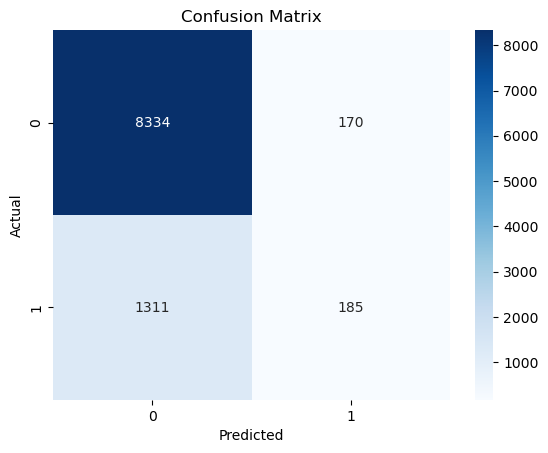

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [65]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

importances = model.named_steps["classifier"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
181,remainder__purchase_lead,0.153493
183,remainder__flight_hour,0.125911
182,remainder__length_of_stay,0.114571
180,remainder__num_passengers,0.050016
187,remainder__flight_duration,0.033667
169,categorical__booking_origin_grouped_Malaysia,0.026431
186,remainder__wants_in_flight_meals,0.026000
185,remainder__wants_preferred_seat,0.021165
160,categorical__booking_origin_grouped_Australia,0.020524
184,remainder__wants_extra_baggage,0.019496


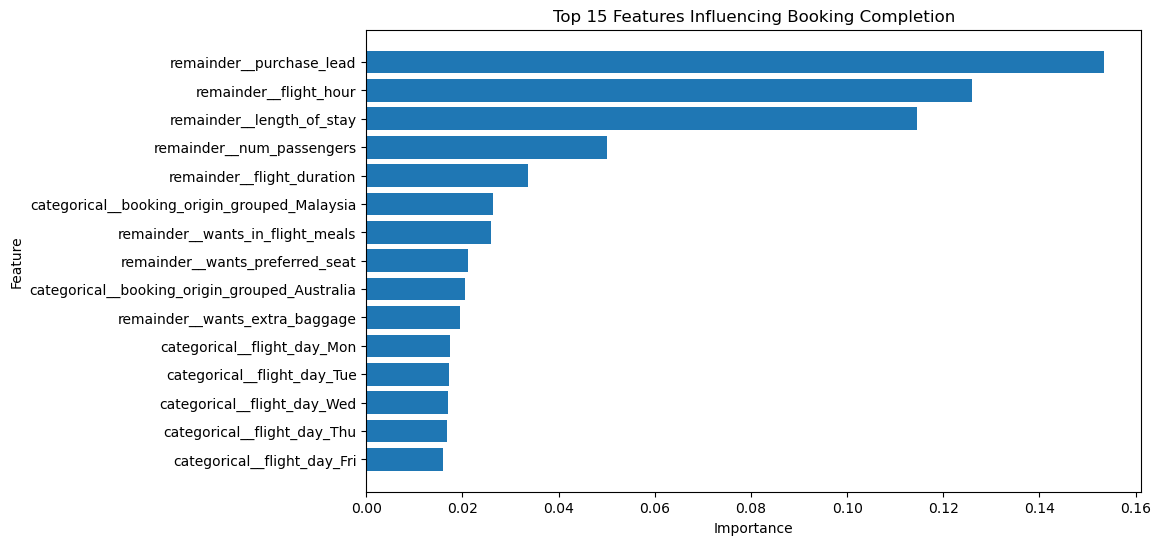

In [66]:
top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Booking Completion")
plt.show()

## 7. Cross-validation

*This cell was run earlier (output also shown in `screenshots/task-2/task2-cross-validation.png`) and later changed to a text cell. It has been restored as code with that output.*

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Cross-validation ROC-AUC scores:")
print(cv_scores)

print("Mean ROC-AUC:", cv_scores.mean())
print("Std ROC-AUC :", cv_scores.std())

Cross-validation ROC-AUC scores:
[0.78796219 0.78655341 0.79041791 0.79013745 0.78709036]
Mean ROC-AUC: 0.7884322646506284
Std ROC-AUC : 0.0015749410819628784


## 8. Final conclusion

This project aimed to develop a machine learning model that could predict whether a customer would complete a flight booking, helping British Airways identify potential customers before their travel.

The analysis began with exploratory data analysis to understand customer booking behaviour and identify potentially useful predictors. Several features showed meaningful differences in booking completion rates, including sales channel, trip type, customer preferences, booking origin, flight hour, and length of stay. Rather than removing variables based only on initial assumptions, the modelling process retained potentially useful features and allowed the machine learning model to determine their predictive contribution.

Feature engineering was performed to make the data more suitable for modelling. The high-cardinality `route` variable was separated into `route_origin` and `route_destination`, while less frequent `booking_origin` categories were grouped into an `Other` category. Categorical variables were then one-hot encoded, while numerical variables were retained in their original form.

A Random Forest classification model was selected because it can capture non-linear relationships and provides feature importance measures that help explain which variables contribute most to predictions. The dataset was divided into training and testing sets using stratification to preserve the target distribution.

The model achieved an **accuracy of 85.19%** and a **ROC-AUC of 0.792** on the test set. However, accuracy alone is not a suitable measure of success because approximately 85% of observations belonged to the non-completed booking class. The model's precision was **52.11%**, while recall was **12.37%**, indicating that the default classification threshold identified only a relatively small proportion of customers who actually completed their bookings. Therefore, the model should be viewed primarily as a useful ranking/discrimination model rather than a highly effective binary classifier at the default threshold.

The model's feature importance analysis identified **purchase lead, flight hour, and length of stay** as the three most influential features. Other useful predictors included number of passengers, flight duration, booking origin, and customer preferences such as in-flight meals, preferred seats, and extra baggage. These results demonstrate that booking behaviour is influenced by a combination of booking timing, trip characteristics, flight information, and customer preferences.

Five-fold stratified cross-validation produced a mean **ROC-AUC of 0.788**, with a very low standard deviation of **0.0016**. The consistency across folds suggests that the model's predictive performance is relatively stable rather than being dependent on a particular train-test split.

### Business Implications

The results suggest that British Airways could use customer and booking characteristics to identify customers with a higher likelihood of completing a booking. In particular, booking lead time, flight timing, and length of stay appear to provide valuable predictive information.

However, the model should not be treated as a perfect yes/no decision system. Its relatively low recall means that many customers who eventually complete a booking would not be identified using the default classification threshold. A potential next step would therefore be to optimise the prediction threshold according to the business objective—for example, prioritising higher recall if British Airways wants to reach more potential customers, or higher precision if marketing resources are limited.

Overall, the project demonstrates a complete machine learning workflow: **understanding the business problem, exploring the data, forming and testing assumptions, engineering features, preprocessing data, training a classification model, evaluating performance, validating model stability, and translating model results into business recommendations.**
